# Geographic main field and magnetic survey azimuth

This demonstration uses IGRF-14 at decimal year 2026.0 and WGS84 ellipsoid height 0 km. Compare four locations using the same ore body, observation height, and grid. Change the two azimuths to see how the horizontal field divides between the survey and strike directions. Compass angles are clockwise from true north, and positive inclination points down.

In [1]:
from pathlib import Path
import sys

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "magnetic_model" / "igrf.py").is_file())
sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import numpy as np

from magnetic_model import Grid, OreBody, simulate_at_location
from magnetic_model.igrf import ALTITUDE_KM, EPOCH, geographic_field

sites = {
    "Golden": (39.7, -105.0),
    "Skagway": (59.45, -135.31),
    "Singapore": (1.35, 103.82),
    "Perth": (-31.95, 115.86),
}
fields = {name: geographic_field(*coordinates) for name, coordinates in sites.items()}
print(f"IGRF-14, decimal year {EPOCH}, height {ALTITUDE_KM:g} km")
print("Site            N (nT)     E (nT)     Down (nT)     I (°)     D (°)      F (nT)      H (nT)")
for name, field in fields.items():
    print(f"{name:11}  {field.north_nt:9.1f}  {field.east_nt:9.1f}  {field.down_nt:11.1f}"
          f"  {field.inclination_deg:8.2f}  {field.declination_deg:8.2f}"
          f"  {field.total_nt:10.1f}  {field.horizontal_nt:10.1f}")

IGRF-14, decimal year 2026.0, height 0 km
Site            N (nT)     E (nT)     Down (nT)     I (°)     D (°)      F (nT)      H (nT)
Golden         20715.7     2747.2      46589.4     65.84      7.55     51061.3     20897.1
Skagway        13790.5     4434.5      53672.5     74.90     17.83     55593.0     14486.0
Singapore      41037.8      156.8      -9348.8    -12.83      0.22     42089.5     41038.1
Perth          23929.7     -637.4     -53333.5    -65.83     -1.53     58459.4     23938.2


## Controlled forward models

Use the 1,600 m square and 5 m cells tested in the rectangular domain study. The body is 80 m wide and 40 m thick, with its top at 40 m depth and susceptibility contrast 0.1 SI. Sample at 10 m above ground. Changing the azimuth changes the survey and strike directions of this 2D section. At each azimuth the idealized body is infinitely extended perpendicular to the survey, so this sweep represents changing the body's orientation relative to the inducing field. It does not represent crossing one fixed finite body from multiple headings.

In [2]:
body = OreBody(width_m=80, thickness_m=40, depth_to_top_m=40, susceptibility=0.1)
grid = Grid(spacing_m=5, nx=320, nz_air=160, nz_ground=160)
azimuths = (0, 90)
results = {
    (name, azimuth): simulate_at_location(
        body, latitude_deg=latitude, longitude_deg=longitude, azimuth_deg=azimuth,
        observation_height_m=10, grid=grid,
    )
    for name, (latitude, longitude) in sites.items()
    for azimuth in azimuths
}
print("Peak absolute exact total-field anomaly (nT) over ±200 m")
for name in sites:
    peaks = []
    for azimuth in azimuths:
        result = results[name, azimuth]
        mask = abs(result.x_m) <= 200
        peaks.append(f"{azimuth}°: {np.max(abs(result.profile_total_anomaly_nt[mask])):.2f}")
    print(f"{name:11}  " + "    ".join(peaks))

Peak absolute exact total-field anomaly (nT) over ±200 m
Golden       0°: 362.03    90°: 328.42
Skagway      0°: 414.49    90°: 401.03
Singapore    0°: 321.10    90°: 16.07
Perth        0°: 414.97    90°: 375.24


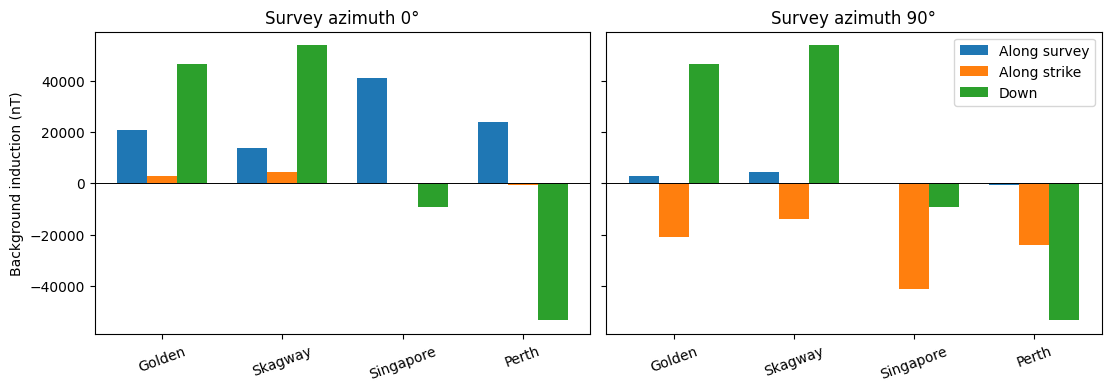

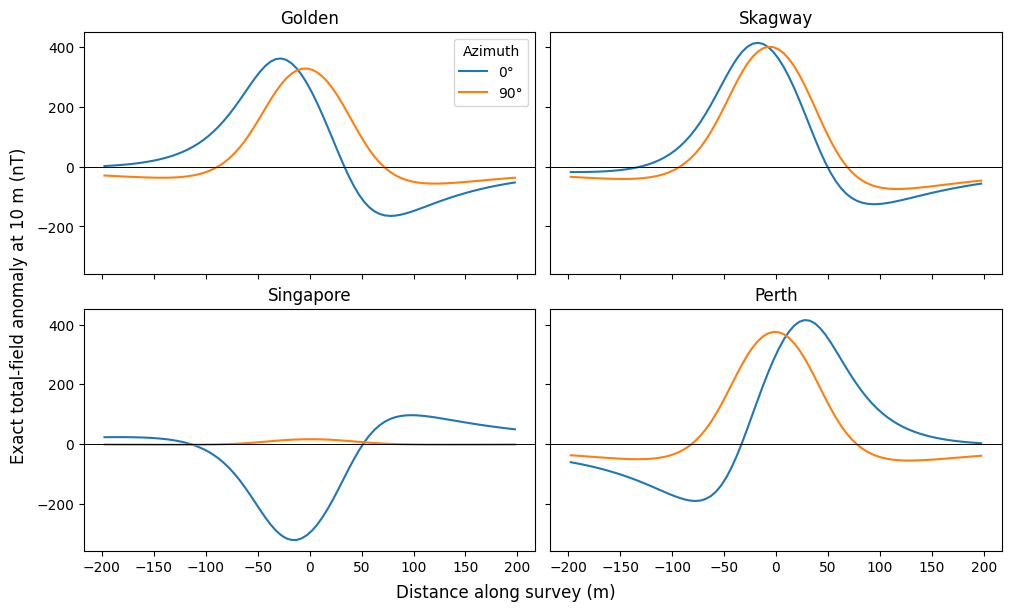

In [3]:
fig, axes = plt.subplots(1, len(azimuths), figsize=(11, 3.8), sharey=True, layout="constrained")
positions = np.arange(len(sites))
for ax, azimuth in zip(np.atleast_1d(axes), azimuths):
    components = np.array([results[name, azimuth].background_nt for name in sites])
    for index, label in enumerate(("Along survey", "Along strike", "Down")):
        ax.bar(positions + (index - 1) * 0.25, components[:, index], 0.25, label=label)
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set_xticks(positions, sites, rotation=20)
    ax.set_title(f"Survey azimuth {azimuth}°")
axes[0].set_ylabel("Background induction (nT)")
axes[-1].legend()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True, layout="constrained")
for ax, name in zip(axes.flat, sites):
    for azimuth in azimuths:
        result = results[name, azimuth]
        mask = abs(result.x_m) <= 200
        ax.plot(result.x_m[mask], result.profile_total_anomaly_nt[mask], label=f"{azimuth}°")
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set_title(name)
axes[0, 0].legend(title="Azimuth")
fig.supxlabel("Distance along survey (m)")
fig.supylabel("Exact total-field anomaly at 10 m (nT)")
plt.show()

## Reading the plots

At 0° the survey and strike components are north and east. At 90° they become east and south, so the strike component is minus north. The down component is invariant under this rotation. The PDE is driven by the cross-section components. Strike still contributes to the magnitude of the inducing field in the exact total-field profile. Singapore's field is much shallower than the fields at the other sites, which makes its cross-section forcing particularly sensitive to azimuth in this example.

IGRF supplies a smooth main field at the chosen epoch. It does not include local crustal anomalies, terrain, or time-dependent external fields. The ore body adds a local perturbation under the same assumptions as the analytical verification notebook. See the repository's IGRF-14 notes for the NOAA/CIRES reference values and the Pyodide check.